# Portefeuille 60/40 : l'effet du rééquilibrage

Un portefeuille 60 % actions / 40 % obligations est l'allocation de référence de la
gestion diversifiée. Ce notebook le construit à partir des données des notebooks
précédents, puis mesure ce que change le fait de remettre périodiquement les poids à
leur cible.

Données : `data/actions_obligations.csv`, 659 séances communes du 19 février 2024 au
25 septembre 2026.

Auteur : KOULEKPOTO Yao Eloge Crédo — octobre 2026

## 1. Choix des deux actifs

Le fichier contient quatre ETF, mais un portefeuille 60/40 n'en demande que deux : une
poche actions et une poche obligations. Les trois ETF actions répliquant le même indice
et affichant une corrélation supérieure à 0,98 (notebook 06), en retenir plusieursµ
n'apporterait aucune diversification.

**MEUD.PA** est retenu pour la poche actions. Sur la période étudiée, il affiche les
frais courants les plus bas des trois (0,07 % par an contre 0,19 % et 0,20 %), la
meilleure performance annualisée (14,08 %) et une réplication physique complète, là où
ETZ.PA passe par un swap dont le coût échappe aux frais affichés.

**IEGA.AS** constitue la poche obligataire : emprunts d'État de la zone euro, volatilité
annualisée de 4,55 % contre 13,28 % pour les actions, corrélation de +0,29 avec elles.

In [33]:
import pandas as pd
ptf_64 = pd.read_csv("data/actions_obligations.csv", index_col = "Date",parse_dates=True)
ptf_64 = ptf_64[["MEUD.PA","IEGA.AS"]]
ptf_64

,MEUD.PA,IEGA.AS
Date,,
2024-02-19,223.820007,103.298965
2024-02-20,223.429993,103.591324
2024-02-21,223.139999,102.987732
2024-02-22,225.250000,103.232941
2024-02-23,226.190002,103.770515
...,...,...
2026-09-21,316.600006,105.489998
2026-09-22,316.950012,105.449997
2026-09-23,315.850006,104.769997


## 2. Construction du portefeuille en buy and hold

On place 60 € en actions et 40 € en obligations au premier jour, puis on ne touche plus
à rien. Chaque poche suit ensuite l'évolution de son ETF : sa valeur à une date donnée
vaut sa mise de départ multipliée par la performance du fonds depuis le premier jour.

Le portefeuille démarre donc à 100, ce qui permet de lire directement sa performance
cumulée en pourcentage.

In [34]:
portfolio_value = pd.DataFrame({"Poche actions": ptf_64["MEUD.PA"]*60/ptf_64["MEUD.PA"].iloc[0],
          "Poche obligations": ptf_64["IEGA.AS"]*40/ptf_64["IEGA.AS"].iloc[0]})
portfolio_value["Portefeuille"] = portfolio_value["Poche actions"] + portfolio_value["Poche obligations"]
portfolio_value

,Poche actions,Poche obligations,Portefeuille
Date,,,
2024-02-19,60.000000,40.000000,100.000000
2024-02-20,59.895448,40.113209,100.008656
2024-02-21,59.817709,39.879482,99.697191
2024-02-22,60.383342,39.974434,100.357775
2024-02-23,60.635331,40.182596,100.817927
...,...,...,...
2026-09-21,84.871771,40.848424,125.720195
2026-09-22,84.965598,40.832934,125.798532
2026-09-23,84.670716,40.569621,125.240337


## 3. La dérive des poids

Le portefeuille a été constitué à 60/40 et plus jamais touché. Sa composition, elle, n'a
aucune raison d'être restée fixe : chaque poche suit son propre actif, et celle qui monte
le plus prend mécaniquement une place croissante dans le total.

La part des actions se calcule à chaque date comme le rapport entre la valeur de la poche
actions et celle du portefeuille.

In [35]:
portfolio_value["Dérive poids actions"] = portfolio_value["Poche actions"]/portfolio_value["Portefeuille"]
portfolio_value

,Poche actions,Poche obligations,Portefeuille,Dérive poids actions
Date,,,,
2024-02-19,60.000000,40.000000,100.000000,0.600000
2024-02-20,59.895448,40.113209,100.008656,0.598903
2024-02-21,59.817709,39.879482,99.697191,0.599994
2024-02-22,60.383342,39.974434,100.357775,0.601681
2024-02-23,60.635331,40.182596,100.817927,0.601434
...,...,...,...,...
2026-09-21,84.871771,40.848424,125.720195,0.675085
2026-09-22,84.965598,40.832934,125.798532,0.675410
2026-09-23,84.670716,40.569621,125.240337,0.676066


<Axes: xlabel='Date', ylabel='Dérive poids actions'>

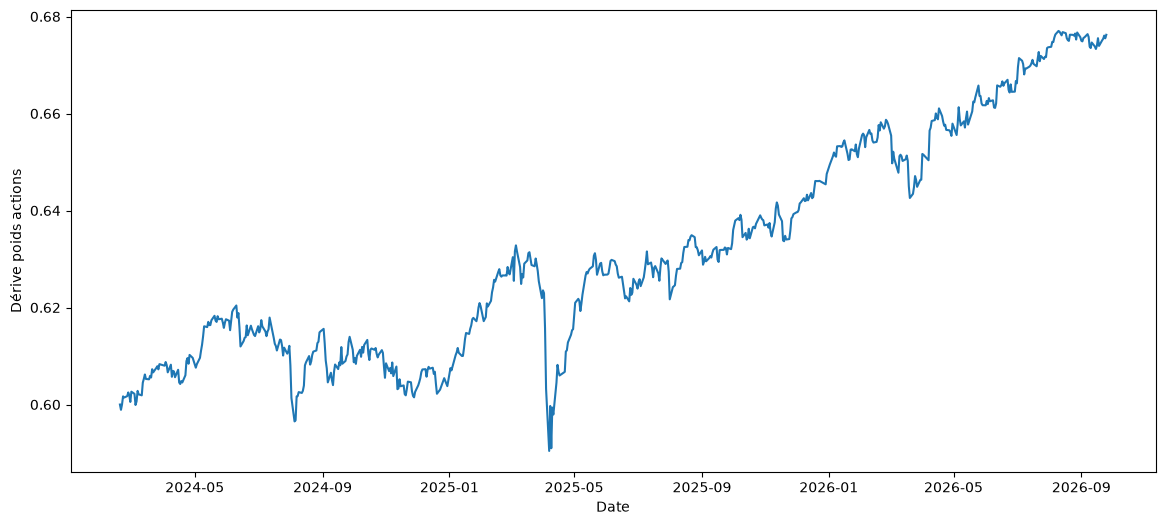

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(14,6))
sns.lineplot(data=portfolio_value["Dérive poids actions"])

La part des actions passe de 60,0 % au premier jour à **67,6 %** au dernier. Elle dérive
dès la deuxième séance et ne revient jamais à sa cible. La mécanique est simple : les
actions ont gagné 40,8 % sur la période, les obligations 0,4 %.

Le graphique montre que cette dérive n'est pas régulière. Elle recule à chaque chute des
marchés actions — le creux d'avril 2025 ramène brièvement les actions sous 60 % — puis
reprend sa progression. Autrement dit, le portefeuille devient d'autant plus exposé aux
actions que celles-ci ont déjà monté, et il allège cette exposition après qu'elles ont
baissé.

C'est l'inverse de ce qu'on voudrait faire, et ce n'est pas le fruit d'une décision :
c'est ce qui arrive par défaut quand on ne fait rien. Un investisseur qui avait choisi
60/40 pour un certain niveau de risque détient aujourd'hui un portefeuille sensiblement
plus risqué que celui qu'il avait voulu.

Le rééquilibrage, qui consiste à remettre périodiquement les poids à leur cible, sera
étudié plus loin dans ce notebook. Avant cela, il faut mesurer ce que ce portefeuille
sans rééquilibrage a produit.

## 4. Rendement et risque du portefeuille

Le portefeuille est maintenant comparé à chacune de ses deux composantes prise isolément,
sur les quatre indicateurs construits dans les notebooks précédents : rendement annualisé,
volatilité annualisée, maximum drawdown et ratio de Sharpe.

Le ratio de Sharpe est calculé avec un taux sans risque de 2 %, hypothèse déjà retenue au
notebook 06 — changer d'hypothèse rendrait les deux notebooks incomparables.

In [37]:
# Performance cumulée 
performance = (portfolio_value[["Poche actions", "Poche obligations", "Portefeuille"]].iloc[-1]-portfolio_value[["Poche actions", "Poche obligations", "Portefeuille"]].iloc[0])/portfolio_value[["Poche actions", "Poche obligations", "Portefeuille"]].iloc[0]
performance

Poche actions        0.408051
Poche obligations    0.011240
Portefeuille         0.249326
dtype: float64

In [38]:
# Rendement annualisé
n_years = (portfolio_value.index[-1] - portfolio_value.index[0]).days/365.25
rend_annual = (1 + performance)**(1/n_years) - 1
rend_annual

Poche actions        0.140775
Poche obligations    0.004311
Portefeuille         0.089453
dtype: float64

In [39]:
# Volatilité annualisée
portfolio_returns = portfolio_value[["Poche actions", "Poche obligations", "Portefeuille"]].pct_change()
portfolio_returns = portfolio_returns.dropna()
volat_annualisee = portfolio_returns.std()*252**0.5
volat_annualisee

Poche actions        0.132819
Poche obligations    0.045509
Portefeuille         0.089472
dtype: float64

In [40]:
# Max drawdown
max_glissant = portfolio_value[["Poche actions", "Poche obligations", "Portefeuille"]].cummax()
drawdown = (portfolio_value[["Poche actions", "Poche obligations", "Portefeuille"]] - max_glissant)/max_glissant
max_dd = drawdown.min()
max_dd

Poche actions       -0.161798
Poche obligations   -0.051223
Portefeuille        -0.105647
dtype: float64

In [41]:
# Ratio de Sharpe à 2%
r_sharpe = (rend_annual-0.02)/volat_annualisee
r_sharpe

Poche actions        0.909322
Poche obligations   -0.344747
Portefeuille         0.776251
dtype: float64

In [42]:
# Tableau récapitulatif
recap = pd.DataFrame({"Rendement annualisé":rend_annual, "Volatilité annualisée": volat_annualisee,
                     "Drawdown max":max_dd, "Ratio de Sharpe 2%":r_sharpe})
recap

,Rendement annualisé,Volatilité annualisée,Drawdown max,Ratio de Sharpe 2%
Poche actions,0.140775,0.132819,-0.161798,0.909322
Poche obligations,0.004311,0.045509,-0.051223,-0.344747
Portefeuille,0.089453,0.089472,-0.105647,0.776251


<Axes: xlabel='Date'>

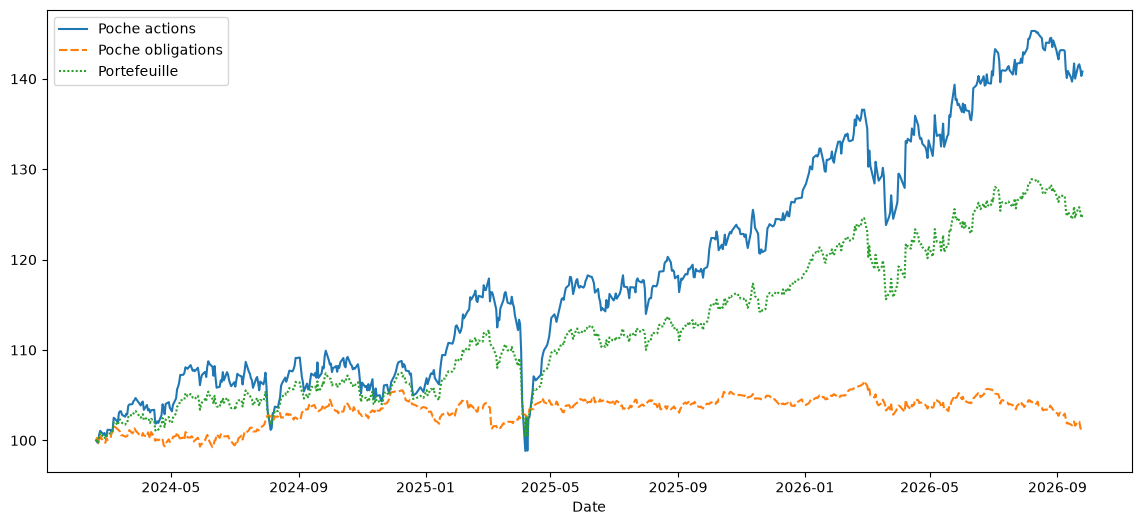

In [43]:
portfolio_b100 = portfolio_value[["Poche actions", "Poche obligations", "Portefeuille"]]*100/portfolio_value[["Poche actions", "Poche obligations", "Portefeuille"]].iloc[0]
plt.figure(figsize=(14,6))
sns.lineplot(data=portfolio_b100)

Le portefeuille 60/40 ne se situe pas à mi-chemin entre ses deux composantes : il penche
nettement du côté des actions. Son rendement annualisé de 8,95 % représente 64 % de celui
des actions seules, et sa volatilité de 8,95 % en représente 67 %. Les 40 % d'obligations
pèsent moins que leur poids nominal, parce que leur contribution au risque comme au
rendement est faible.

(La proximité entre rendement et volatilité, tous deux à 8,95 %, est une coïncidence
numérique sans signification.)

Le maximum drawdown est l'indicateur le plus parlant : −10,56 % contre −16,18 % pour les
actions seules. En avril 2025, le portefeuille a reculé de 10,6 % là où un investisseur
100 % actions perdait 16,2 %. Six points de perte évités au pire moment, c'est ce que les
40 % d'obligations ont acheté.

Le ratio de Sharpe arbitre entre les deux effets : 0,78 pour le portefeuille contre 0,91
pour les actions seules. Rapporté au risque pris, le 60/40 fait un peu moins bien sur
cette période. Le résultat n'a rien de surprenant sur une fenêtre de deux ans et demi où
les actions ont gagné 40 % sans crise durable, et où les obligations n'ont rien rapporté.
Il serait inversé sur une période de marché baissier.

## 5. Le rééquilibrage trimestriel

Rééquilibrer consiste à remettre les poids à leur cible à intervalles réguliers. À chaque
fin de trimestre, on vend une partie de la poche qui a trop grossi et on achète l'autre
avec le produit de la vente. La valeur totale du portefeuille ne change pas à cet instant,
seule sa composition change : aucun argent frais n'est apporté.

L'opération se fait ici tous les trimestres, la fréquence la plus courante en gestion
diversifiée. Entre deux dates de rééquilibrage, le portefeuille se comporte comme le buy
and hold de la section 2 : les poids dérivent librement, puis sont ramenés à 60/40.

In [44]:
# Dernière séance réellement cotée de chaque trimestre
rebalance_dates = portfolio_value["Portefeuille"].resample("QE").apply(lambda g: g.index[-1])
rebalance_dates = rebalance_dates[:-1]   # le 25/09/2026 est la fin de l'historique, pas un rééquilibrage
rebalance_dates

Date
2024-03-31   2024-03-28
2024-06-30   2024-06-28
2024-09-30   2024-09-30
2024-12-31   2024-12-30
2025-03-31   2025-03-31
2025-06-30   2025-06-30
2025-09-30   2025-09-30
2025-12-31   2025-12-30
2026-03-31   2026-03-31
2026-06-30   2026-06-30
Freq: QE-DEC, Name: Portefeuille, dtype: datetime64[us]

In [45]:
# Bornes des segments : première séance, 10 dates de rééquilibrage, dernière séance
bornes = [ptf_64.index[0]] + list(rebalance_dates) + [ptf_64.index[-1]]

# Reconstruction du portefeuille rééquilibré, segment par segment
valeur = 100
segments = []

for debut, fin in zip(bornes[:-1], bornes[1:]):
    seg = ptf_64.loc[debut:fin]
    actions = 0.6 * valeur * seg["MEUD.PA"] / seg["MEUD.PA"].iloc[0]
    obligations = 0.4 * valeur * seg["IEGA.AS"] / seg["IEGA.AS"].iloc[0]
    valeur = actions.iloc[-1] + obligations.iloc[-1]

    seg_val = pd.DataFrame({"Poche actions": actions, "Poche obligations": obligations})
    if fin != bornes[-1]:
        seg_val = seg_val.iloc[:-1]   # le jour du rééquilibrage appartient au segment suivant
    segments.append(seg_val)

rebalanced = pd.concat(segments)
rebalanced["Portefeuille"] = rebalanced["Poche actions"] + rebalanced["Poche obligations"]
rebalanced["Dérive poids actions"] = rebalanced["Poche actions"] / rebalanced["Portefeuille"]
rebalanced

,Poche actions,Poche obligations,Portefeuille,Dérive poids actions
Date,,,,
2024-02-19,60.000000,40.000000,100.000000,0.600000
2024-02-20,59.895448,40.113209,100.008656,0.598903
2024-02-21,59.817709,39.879482,99.697191,0.599994
2024-02-22,60.383342,39.974434,100.357775,0.601681
2024-02-23,60.635331,40.182596,100.817927,0.601434
...,...,...,...,...
2026-09-21,75.842262,48.679433,124.521695,0.609069
2026-09-22,75.926107,48.660974,124.587081,0.609422
2026-09-23,75.662598,48.347181,124.009779,0.610134


In [46]:
# Contrôle : part des actions ramenée à 60 % à chaque rééquilibrage
rebalanced.loc[list(rebalance_dates), "Dérive poids actions"]

Date
2024-03-28    0.6
2024-06-28    0.6
2024-09-30    0.6
2024-12-30    0.6
2025-03-31    0.6
2025-06-30    0.6
2025-09-30    0.6
2025-12-30    0.6
2026-03-31    0.6
2026-06-30    0.6
Name: Dérive poids actions, dtype: float64

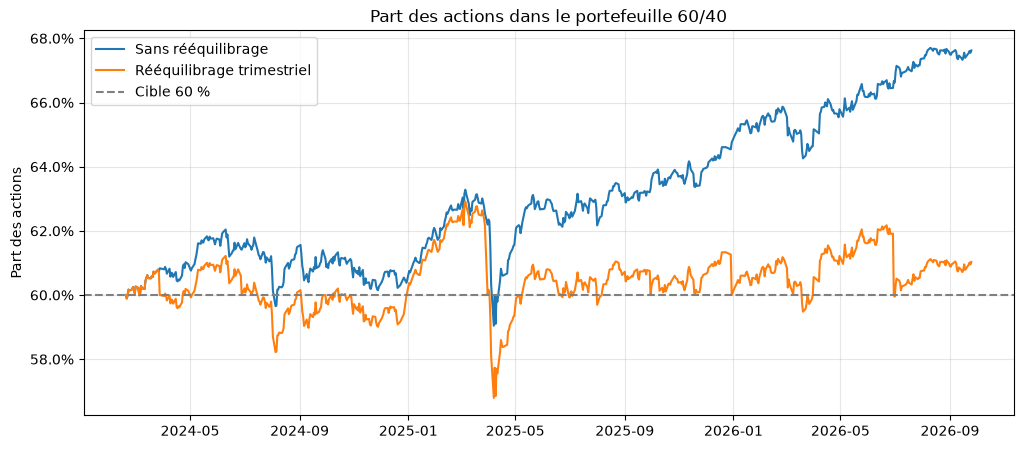

In [47]:
# Dérive de la part des actions : avec et sans rééquilibrage
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(portfolio_value["Dérive poids actions"], label="Sans rééquilibrage")
ax.plot(rebalanced["Dérive poids actions"], label="Rééquilibrage trimestriel")
ax.axhline(0.60, color="grey", linestyle="--", label="Cible 60 %")
ax.set_title("Part des actions dans le portefeuille 60/40")
ax.set_ylabel("Part des actions")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.legend()
ax.grid(alpha=0.3)
fig.savefig("images/derive_poids.png", dpi=150, bbox_inches="tight")

In [48]:
# Indicateurs de rendement et de risque d'une série de valeurs de portefeuille
def indicateurs(serie, rf=0.02):
    n_years = (serie.index[-1] - serie.index[0]).days / 365.25
    perf = serie.iloc[-1] / serie.iloc[0] - 1
    rend = (1 + perf) ** (1 / n_years) - 1
    vol = serie.pct_change().dropna().std() * 252 ** 0.5
    mdd = (serie / serie.cummax() - 1).min()
    return pd.Series({"Performance cumulée": perf,
                      "Rendement annualisé": rend,
                      "Volatilité annualisée": vol,
                      "Drawdown max": mdd,
                      "Sharpe (2 %)": (rend - rf) / vol})

comparaison = pd.DataFrame({
    "Sans rééquilibrage": indicateurs(portfolio_value["Portefeuille"]),
    "Rééquilibrage trimestriel": indicateurs(rebalanced["Portefeuille"]),
}).T

comparaison.style.format({"Performance cumulée": "{:.2%}",
                          "Rendement annualisé": "{:.2%}",
                          "Volatilité annualisée": "{:.2%}",
                          "Drawdown max": "{:.2%}",
                          "Sharpe (2 %)": "{:.2f}"})

,Performance cumulée,Rendement annualisé,Volatilité annualisée,Drawdown max,Sharpe (2 %)
Sans rééquilibrage,24.93%,8.95%,8.95%,-10.56%,0.78
Rééquilibrage trimestriel,23.70%,8.53%,8.65%,-10.29%,0.75


| | Performance cumulée | Rendement annualisé | Volatilité annualisée | Drawdown max | Sharpe (2 %) |
|---|---|---|---|---|---|
| Sans rééquilibrage | 24,93 % | 8,95 % | 8,95 % | −10,56 % | 0,78 |
| Rééquilibrage trimestriel | 23,70 % | 8,53 % | 8,65 % | −10,29 % | 0,75 |

Le rééquilibrage tient son rôle premier : la part des actions reste comprise entre 57 % et
63 % sur toute la période, contre une dérive continue jusqu'à 67,6 % sans intervention.

Il coûte en revanche 0,42 point de rendement annualisé. Le mécanisme l'explique : chaque
trimestre, il vend des actions qui ont monté pour racheter des obligations qui n'ont
presque rien rapporté. Sur une période de hausse quasi continue des actions, c'est un
manque à gagner.

En échange, le risque recule légèrement : 0,30 point de volatilité et 0,27 point de
drawdown en moins. L'écart reste faible parce que la dérive l'est aussi sur 2,6 ans ; sur
une décennie haussière, un portefeuille jamais rééquilibré dépasserait 75 % d'actions et
l'écart de risque deviendrait substantiel.

Le rééquilibrage ne prévoit rien. Celui du 31 mars 2025 ramène les actions à 60 % quelques
jours avant le choc d'avril, et leur part tombe à 57 % au creux. Il corrige une dérive
passée, sans anticiper les mouvements à venir.

**Le rééquilibrage ne vise pas à gagner plus, mais à tenir le niveau de risque choisi.**
Sur cette fenêtre, ce choix a coûté du rendement. Il en rapporterait sur une période où
les actions reculent durablement.

## Conclusion

Un portefeuille 60/40 constitué en février 2024 et jamais touché a gagné 24,93 % en 2,6
ans, mais il n'était plus un 60/40 à l'arrivée : la hausse des actions a porté leur part
à 67,6 %. Sans décision de l'investisseur, son exposition au risque a augmenté.

Rééquilibré chaque trimestre, le même portefeuille reste proche de sa cible, pour un
rendement inférieur de 0,42 point par an et un risque légèrement plus faible. Sur cette
période de hausse des actions, la discipline a coûté du rendement ; elle protège surtout
contre la dérive silencieuse du profil de risque.

Limites : les frais de transaction et la fiscalité des arbitrages ne sont pas modélisés,
ce qui pénaliserait davantage la version rééquilibrée ; la fenêtre de 2,6 ans ne comprend
aucun marché baissier durable ; une seule fréquence de rééquilibrage a été testée.